# 01 · Знакомство с данными

Здесь показано, как выглядят данные о продажах на CSFloat, и разобраны два факта, на
которых построен весь подход к моделям:

1. для обычного предмета собственная оценка цены от CSFloat уже очень точна;
2. но она не учитывает наклейки и брелоки, а на них приходится большая часть денег и
   большая часть ошибок.

Если полный датасет есть в рабочей папке, ноутбук работает на нём. Если нет, берётся
сэмпл из `data/sample/` (5% скинов).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from skinprice import paths
from skinprice.data.io import load_tables
from skinprice.features.build import build_feature_table, feature_path, load_features
from skinprice.research.labels import value
from skinprice.research.plots import NEUTRAL, SERIES, apply_style, bar_labels
from skinprice.research.trading import TOM_EDGES, TOM_LABELS, addon_cents, time_on_market_days

apply_style()
COLUMNS = ["name", "event_time", "listed_at", "split", "price_cents", "anchor_cents", "float_value",
           "sticker_count", "keychain_count", "log_sticker_sum_ref_price", "log_keychain_ref_price"]
if feature_path().exists():
    df, source = load_features(columns=COLUMNS), "полный датасет"
else:
    df, source = build_feature_table(load_tables(paths.SAMPLE_DIR)), "встроенный сэмпл 5%"
df["segment"] = np.where(df["sticker_count"] > 0, "craft", np.where(df["keychain_count"] > 0, "charm", "clean"))
print(f"{source}: {len(df):,} продаж с {df.event_time.min():%Y-%m-%d} по {df.event_time.max():%Y-%m-%d}")

полный датасет: 821,216 продаж с 2023-10-02 по 2026-08-10


## Сколько данных и как они разделены

История продаж начинается в 2023 году, но на полную мощность сборщик работал только с
июля 2026, поэтому большинство продаж свежие.

Данные разделены **по времени**, как в реальной жизни: модель учится на прошлом, а
проверяется на будущем, которого не видела.

- Самые новые 20% продаж — **тест**: на них считается итоговая точность.
- 10% перед ними — **валидация**: по ней решается, когда остановить обучение и какой
  ширины делать вилку цен.
- Всё остальное — **обучение**.

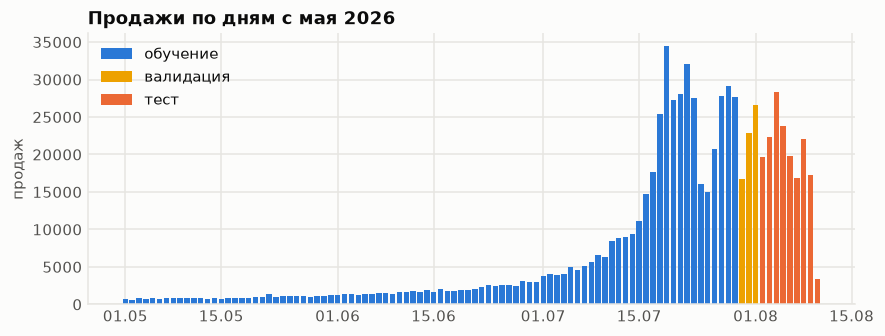

,продаж,с,по
часть,,,
обучение,574849,2023-10-02,2026-07-29
валидация,82123,2026-07-29,2026-08-02
тест,164244,2026-08-02,2026-08-10


In [2]:
SPLIT_NAMES = {"train": "обучение", "val": "валидация", "test": "тест"}
daily = df.set_index("event_time").resample("D").size()
daily = daily[daily.index >= "2026-05-01"]
fig, ax = plt.subplots(figsize=(9, 3.2))
colors = {"train": SERIES[0], "val": SERIES[3], "test": SERIES[1]}
split_by_day = df.set_index("event_time")["split"].astype(str).resample("D").agg(lambda s: s.mode().iat[0] if len(s) else None)
for split, color in colors.items():
    days = split_by_day[split_by_day == split].index.intersection(daily.index)
    ax.bar(days, daily[days], width=0.8, color=color, label=SPLIT_NAMES[split])
ax.set_title("Продажи по дням с мая 2026")
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d.%m"))
ax.legend(loc="upper left")
ax.set_ylabel("продаж")
plt.show()
spans = df.groupby(df["split"].astype(str))["event_time"].agg(["size", "min", "max"]).reindex(["train", "val", "test"])
spans["min"], spans["max"] = spans["min"].dt.strftime("%Y-%m-%d"), spans["max"].dt.strftime("%Y-%m-%d")
spans.rename(index=SPLIT_NAMES, columns={"size": "продаж", "min": "с", "max": "по"}).rename_axis("часть")

## Цены и сегменты

Цены отличаются в сотни тысяч раз: от нескольких центов до тысяч долларов. Поэтому
модели работают с логарифмом цены, а ошибка измеряется в процентах. Главная метрика —
**медианная ошибка**: у половины продаж ошибка меньше неё, у половины больше.

Примерно пятая часть продаж — **крафты**, то есть оружие с наклейками.

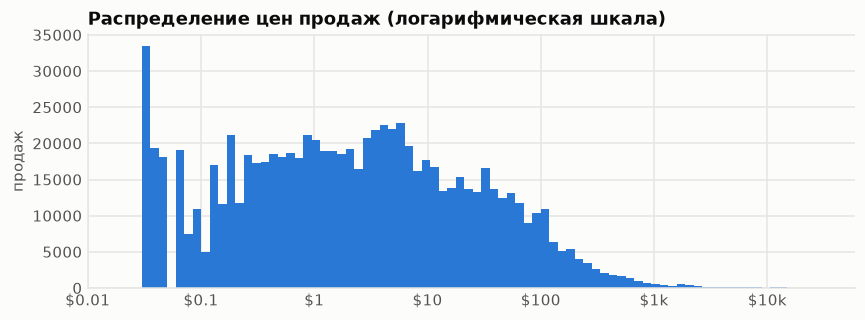

,продаж,"оборот, $","доля продаж, %","доля оборота, %"
сегмент,,,,
с брелоком,10165,788695.5,1.2,2.6
обычный предмет,664425,13569088.2,80.9,45.3
крафт,146626,15586004.6,17.9,52.1


In [3]:
fig, ax = plt.subplots(figsize=(9, 3))
ax.hist(np.log10(df["price_cents"] / 100), bins=80, color=SERIES[0])
ax.set_xticks([-2, -1, 0, 1, 2, 3, 4], ["$0.01", "$0.1", "$1", "$10", "$100", "$1k", "$10k"])
ax.set_title("Распределение цен продаж (логарифмическая шкала)")
ax.set_ylabel("продаж")
plt.show()
seg = df.groupby("segment").agg(sales=("price_cents", "size"), turnover_usd=("price_cents", lambda s: s.sum() / 100))
seg["share_of_sales"] = 100 * seg["sales"] / seg["sales"].sum()
seg["share_of_turnover"] = 100 * seg["turnover_usd"] / seg["turnover_usd"].sum()
seg.index = seg.index.map(value)
seg.round(1).rename(columns={"sales": "продаж", "turnover_usd": "оборот, $", "share_of_sales": "доля продаж, %",
                             "share_of_turnover": "доля оборота, %"}).rename_axis("сегмент")

## Факт 1: для обычного предмета оценка CSFloat и есть цена

`anchor` — это оценка CSFloat (`reference.predicted_price`) за вычетом стоимости брелока,
которую она уже включает. Для обычных предметов без наклеек и брелоков отношение
«цена / оценка» сосредоточено ровно вокруг 1. Большие отклонения встречаются почти
только у самых дешёвых предметов, где цена меняется целыми центами.

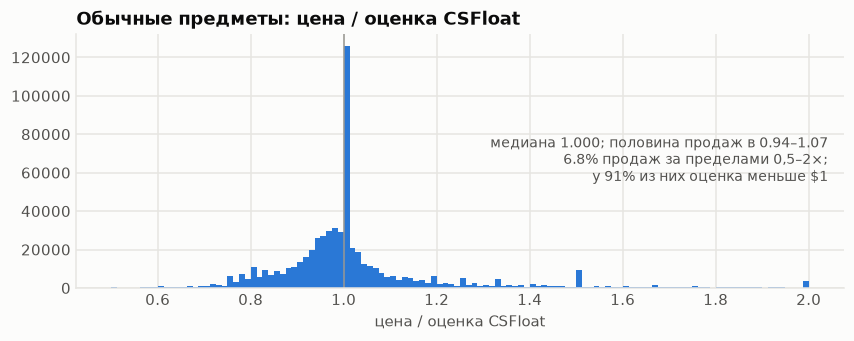

In [4]:
clean = df[df["segment"] == "clean"]
ratio = clean["price_cents"] / clean["anchor_cents"]
q = ratio.quantile([0.25, 0.5, 0.75])
fig, ax = plt.subplots(figsize=(9, 3))
outside_mask = (ratio < 0.5) | (ratio > 2)
outside = float(outside_mask.mean() * 100)
cheap = float((clean.loc[outside_mask, "anchor_cents"] < 100).mean() * 100)
ax.hist(ratio[(ratio >= 0.5) & (ratio <= 2)], bins=120, color=SERIES[0])
ax.axvline(1, color=NEUTRAL, linewidth=1)
ax.set_title("Обычные предметы: цена / оценка CSFloat")
ax.annotate(f"медиана {q[0.5]:.3f}; половина продаж в {q[0.25]:.2f}–{q[0.75]:.2f}\n"
            f"{outside:.1f}% продаж за пределами 0,5–2×;\nу {cheap:.0f}% из них оценка меньше $1",
            (0.98, 0.6), xycoords="axes fraction", ha="right", va="top", color="#52514e", fontsize=9)
ax.set_xlabel("цена / оценка CSFloat")
plt.show()

## Факт 2: оценка CSFloat не видит наклеек

Чем дороже наклейки на оружии, тем сильнее цена уходит вверх от оценки. Поэтому модели
учатся предсказывать именно это отклонение, то есть **наценку** к оценке CSFloat, а не
цену с нуля. Это главное решение в проекте; эксперимент 01 измеряет, что оно даёт.

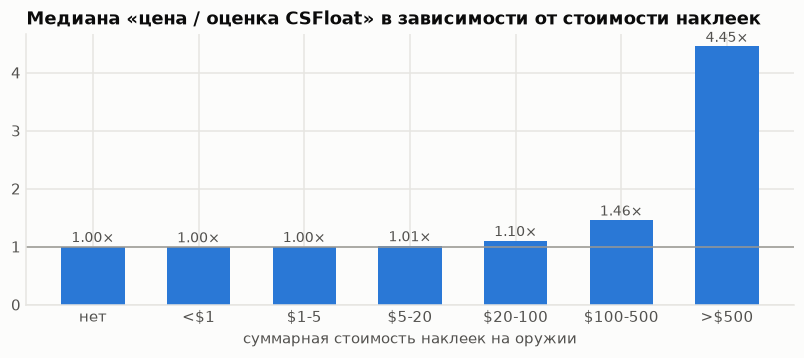

In [5]:
sticker_value = np.expm1(df["log_sticker_sum_ref_price"]) / 100
bands = pd.cut(sticker_value.where(df["sticker_count"] > 0, -1), [-np.inf, 0, 1, 5, 20, 100, 500, np.inf],
               labels=["нет", "<$1", "$1-5", "$5-20", "$20-100", "$100-500", ">$500"])
by_band = (df["price_cents"] / df["anchor_cents"]).groupby(bands, observed=True).median()
fig, ax = plt.subplots(figsize=(9, 3.2))
bars = ax.bar(by_band.index.astype(str), by_band.values, width=0.6, color=SERIES[0])
bar_labels(ax, bars, "{:.2f}×", horizontal=False)
ax.axhline(1, color=NEUTRAL, linewidth=1)
ax.set_title("Медиана «цена / оценка CSFloat» в зависимости от стоимости наклеек")
ax.set_xlabel("суммарная стоимость наклеек на оружии")
plt.show()

Какая часть стоимости наклеек доходит до цены оружия? Очень небольшая: у дорогих крафтов
всего несколько процентов, и больше, когда наклейки дешёвые по сравнению с самим
оружием. Наклеенную наклейку нельзя снять и продать отдельно, поэтому покупатель платит
за неё намного меньше её «магазинной» цены.

Эта кривая («pass-through») ещё пригодится: бэктест торговли (эксперимент 07) оценивает
по ней стоимость крафтов.

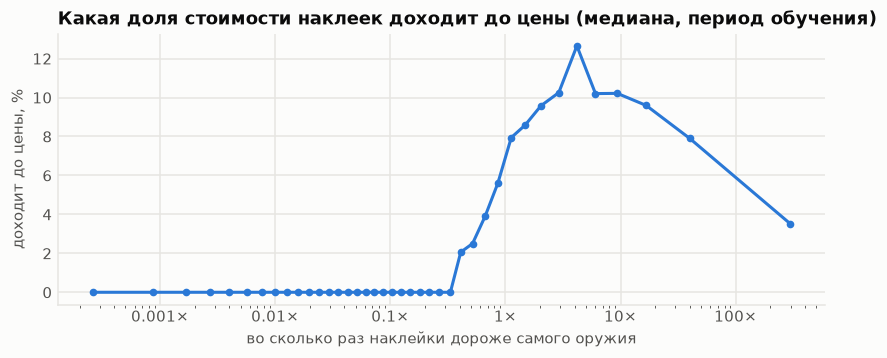

In [6]:
from skinprice.research.trading import passthrough_curve

xs, betas = passthrough_curve(df[df["split"] == "train"])
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(10 ** xs, betas * 100, color=SERIES[0], marker="o", markersize=4)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:g}×"))
ax.set_xlabel("во сколько раз наклейки дороже самого оружия")
ax.set_ylabel("доходит до цены, %")
ax.set_title("Какая доля стоимости наклеек доходит до цены (медиана, период обучения)")
plt.show()

## Насколько шумный сам рынок?

Одинаковые обычные предметы (то же название, float в пределах 0,005), проданные в один
день, всё равно уходят по разным ценам. Медианное отклонение от медианы их группы
показывает, точнее какого уровня в принципе нельзя предсказать цену ликвидных
предметов.

Шум небольшой: в один и тот же день одинаковые ликвидные предметы продаются с разницей
около 1%, а предметы дешевле $1 чаще всего за один и тот же цент. В исходном отчёте
«одинаковые» определялись мягче, и там получилось 9,4%. Эксперимент 06 сравнивает
модель с этим пределом на тех же продажах.

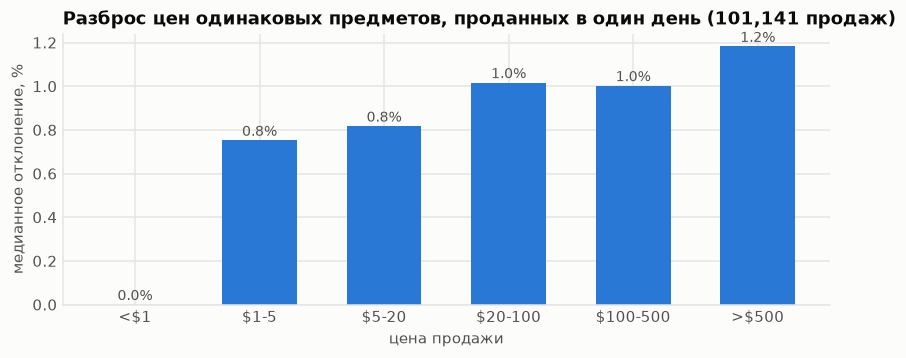

In [7]:
c = clean[clean["float_value"].notna()].copy()
c["day"] = c["event_time"].dt.floor("D")
c["fbin"] = (c["float_value"] / 0.005).astype(int)
g = c.groupby(["name", "day", "fbin"])["price_cents"]
c["n"], c["med"] = g.transform("size"), g.transform("median")
twins = c[c["n"] >= 3]
band = pd.cut(twins["price_cents"], [0, 100, 500, 2000, 10000, 50000, np.inf],
              labels=["<$1", "$1-5", "$5-20", "$20-100", "$100-500", ">$500"], right=False)
spread = (np.abs(twins["price_cents"] - twins["med"]) / twins["price_cents"] * 100).groupby(band, observed=True).median()
fig, ax = plt.subplots(figsize=(9, 3.2))
bars = ax.bar(spread.index.astype(str), spread.values, width=0.6, color=SERIES[0])
bar_labels(ax, bars, "{:.1f}%", horizontal=False)
ax.set_title(f"Разброс цен одинаковых предметов, проданных в один день ({len(twins):,} продаж)")
ax.set_ylabel("медианное отклонение, %")
ax.set_xlabel("цена продажи")
plt.show()

## Сколько лот висит на продаже

Время от выставления лота (`listed_at`) до продажи (`event_time`). Большую долю лотов
покупают в первые минуты после выставления, в основном это делают боты. Поэтому важно,
мог ли человек вообще успеть купить дешёвый лот (эксперимент 07).

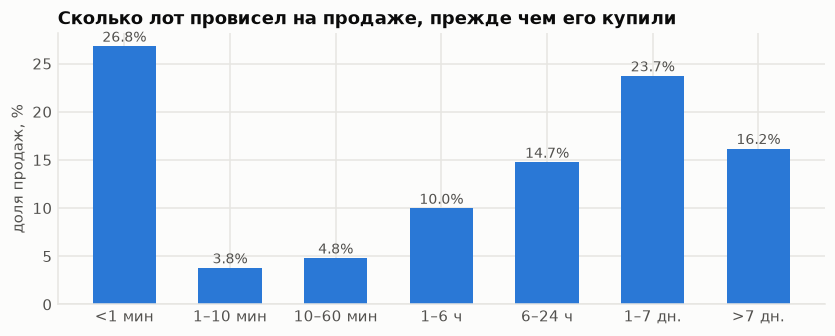

In [8]:
tom = time_on_market_days(df)
buckets = pd.cut(tom[tom >= 0], TOM_EDGES, labels=TOM_LABELS, include_lowest=True).value_counts(normalize=True).reindex(TOM_LABELS) * 100
fig, ax = plt.subplots(figsize=(9, 3.2))
bars = ax.bar([value(label) for label in buckets.index], buckets.values, width=0.6, color=SERIES[0])
bar_labels(ax, bars, "{:.1f}%", horizontal=False)
ax.set_title("Сколько лот провисел на продаже, прежде чем его купили")
ax.set_ylabel("доля продаж, %")
plt.show()